In [1]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Prophet. Часть 3: внешняя информация и «неудобные» данные

В частях 1–2 ряд описывался только функциями времени: тренд, сезонности, праздники. Здесь три темы, где этого мало или где данные устроены не так, как ожидает дефолтный Prophet:

1. **Регрессоры** — внешние ряды в матрице $X$. Главный вопрос: откуда взять их значения в будущем.
2. **Шоки** (COVID-локдауны) — разовые провалы, которые дефолтная модель принимает за изменения тренда.
3. **Не-дневные данные** — часовые и 5-минутные ряды, регулярные пропуски, месячные данные.



In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot
from prophet.utilities import regressor_coefficients

logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.WARNING)
plt.rcParams["figure.figsize"] = (12, 4)


def mae(y_true: pd.Series, y_pred: pd.Series) -> float:
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))

## 1. Регрессоры

`add_regressor(name)` добавляет столбец `name` в матрицу $X$ — так же, как праздник или гармонику Фурье. Отличия от праздника:
- значение может быть любым числом, а не только 0/1;
- небинарный регрессор **стандартизуется** ($(x - \mu)/\sigma$, `standardize='auto'`), чтобы приор $\beta \sim N(0, \text{prior\_scale})$ имел смысл независимо от единиц измерения;
- по умолчанию `prior_scale = holidays_prior_scale`, режим — `seasonality_mode`.

Обязательное условие: столбец должен быть **и в истории, и в `future`**.

### 1.1. Регрессор с известным будущим: `nfl_sunday`

Пример из документации: воскресенья сезона NFL на ряде Пейтона Мэннинга. Календарь известен на годы вперёд.

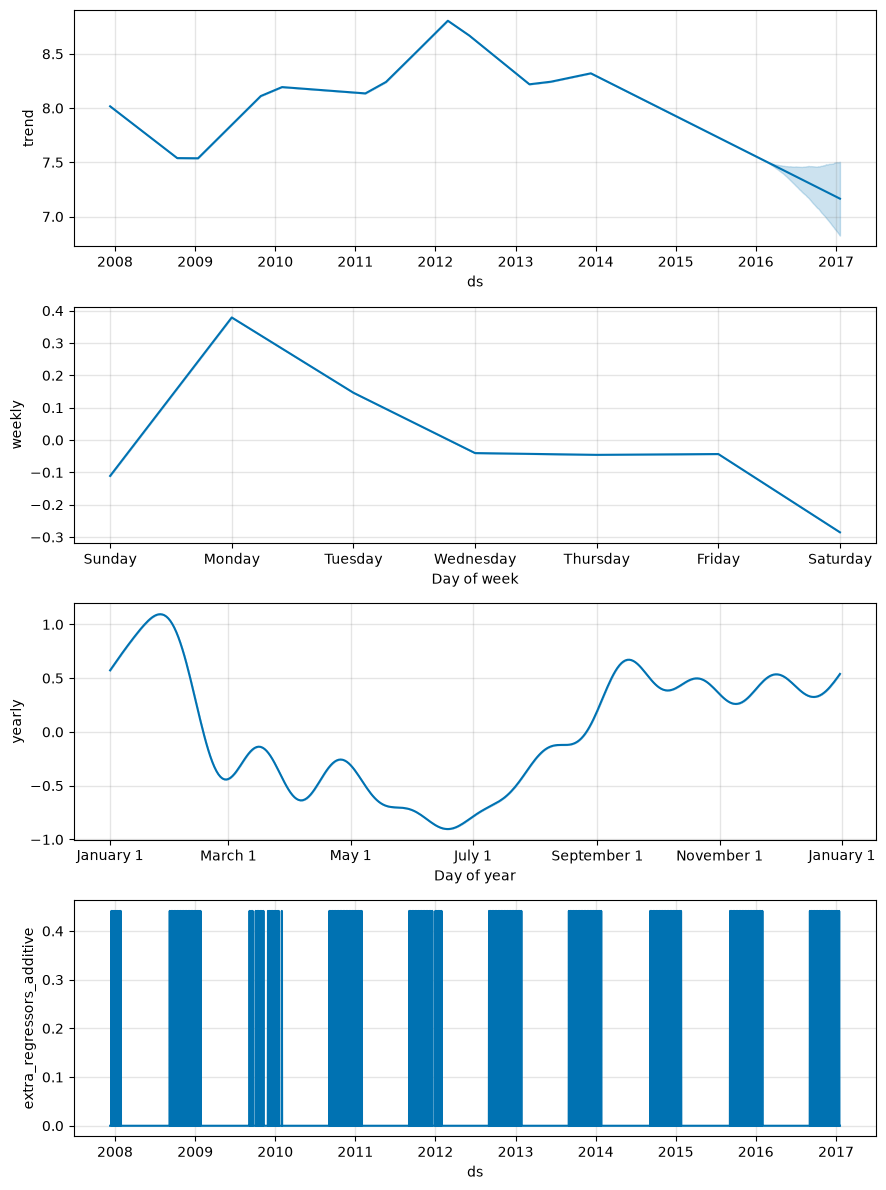

In [3]:
df = pd.read_csv("../data/example_wp_log_peyton_manning.csv", parse_dates=["ds"])


def nfl_sunday(ds: pd.Series) -> pd.Series:
    return ((ds.dt.dayofweek == 6) & ((ds.dt.month > 8) | (ds.dt.month < 2))).astype(int)


df["nfl_sunday"] = nfl_sunday(df["ds"])

m = Prophet()
m.add_regressor("nfl_sunday")
m.fit(df)

future = m.make_future_dataframe(periods=365)
future["nfl_sunday"] = nfl_sunday(future["ds"])
forecast = m.predict(future)
fig = m.plot_components(forecast)

На графике компонент регрессоры собраны в `extra_regressors_additive`. Коэффициенты в **исходной шкале** $y$ возвращает `regressor_coefficients`: `coef` — на сколько меняется прогноз при росте регрессора на единицу (`center` — среднее, вычтенное при стандартизации; у бинарного регрессора 0).

In [4]:
regressor_coefficients(m)

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,nfl_sunday,additive,0.0,0.441279,0.441279,0.441279


Бинарный регрессор с известным будущим — это ровно праздник с окном 0. Проверим: зададим те же воскресенья таблицей `holidays`. Приоры у двух вариантов одинаковые (`holidays_prior_scale`), столбцы $X$ одинаковые — значит, и оценка совпадёт.

In [5]:
nfl_dates = pd.concat([df["ds"], future["ds"]]).drop_duplicates()
nfl_holidays = pd.DataFrame({"holiday": "nfl_sunday", "ds": nfl_dates[nfl_sunday(nfl_dates) == 1]})

m_hol = Prophet(holidays=nfl_holidays).fit(df.drop(columns="nfl_sunday"))
forecast_hol = m_hol.predict(future[["ds"]])
print("эффект регрессора:", forecast.loc[future["nfl_sunday"] == 1, "nfl_sunday"].iloc[0].round(4))
print("эффект праздника: ", forecast_hol.loc[future["nfl_sunday"] == 1, "nfl_sunday"].iloc[0].round(4))

эффект регрессора: 0.4413
эффект праздника:  0.4413


`add_regressor` — более общий интерфейс: регрессор не обязан быть бинарным и может быть другим временным рядом. Но тогда возникает главный вопрос — **где взять его будущие значения**.

### 1.2. Регрессор с неизвестным будущим: погода

Ежедневные поездки на велосипеде в Окленде (`Volume`) с дождём (`Rain`, мм) и температурой (`Temp`, °C) — это данные из ноутбука, на который ссылается документация. Прогнозируем зиму 2019/20 (до COVID).

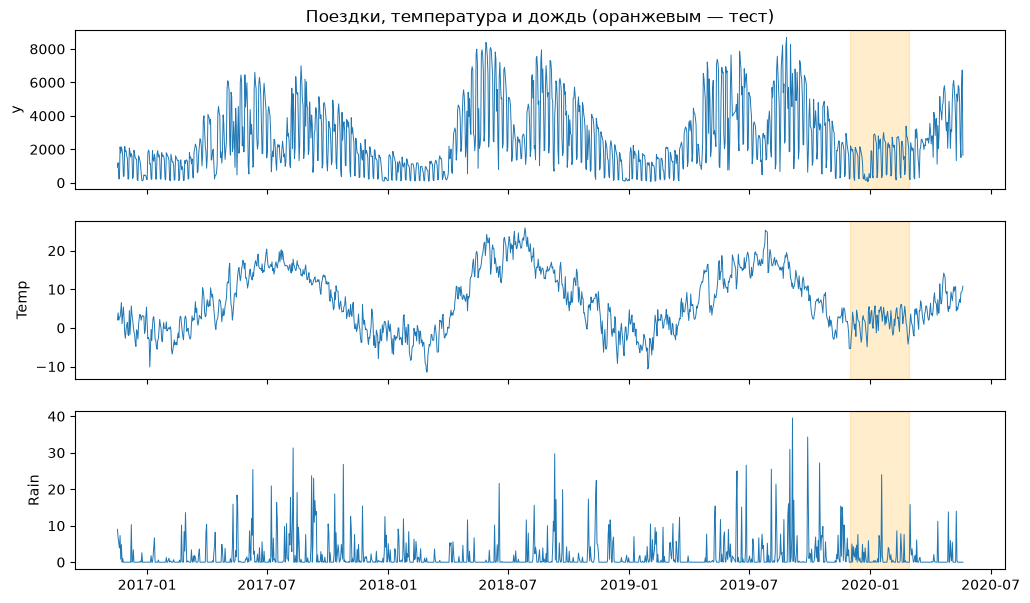

In [8]:
bikes = pd.read_csv("../data/bikerides_day.csv", parse_dates=["Date"]).rename(columns={"Date": "ds", "Volume": "y"})
test_start, test_end = pd.Timestamp("2019-12-01"), pd.Timestamp("2020-02-29")
train = bikes[bikes["ds"] < test_start]
test = bikes[bikes["ds"].between(test_start, test_end)]

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, col in zip(axes, ["y", "Temp", "Rain"]):
    ax.plot(bikes["ds"], bikes[col], lw=0.7)
    ax.axvspan(test_start, test_end, color="orange", alpha=0.2)
    ax.set_ylabel(col)
axes[0].set_title("Поездки, температура и дождь (оранжевым — тест)");

In [9]:
m_weather = Prophet()
m_weather.add_regressor("Rain")
m_weather.add_regressor("Temp")
m_weather.fit(train)
regressor_coefficients(m_weather)

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,Rain,additive,2.038147,-51.370662,-51.370662,-51.370662
1,Temp,additive,7.277929,91.902367,91.902367,91.902367


+1 °C — около +100 поездок в день, +1 мм дождя — около −50. Регрессоры осмысленные. Теперь — ловушка.

**«Подставили факт погоды в будущее».** `m_weather.predict(test)` возьмёт `Rain` и `Temp` из `test` — то есть **реальную погоду**, которой в момент прогноза ещё нет. Такая оценка качества — это оценка модели, которой у нас никогда не будет (утечка будущего). Честных вариантов два:
- подставить **прогноз** погоды (метеосервиса — для горизонта в несколько дней);
- спрогнозировать регрессор самим.

Второе встроено в Prophet с версии 1.4: `add_regressor(..., regressor_predictor=True)` обучает для регрессора **вложенную Prophet-модель** (можно передать словарь параметров её конструктора). В `predict` будущие значения регрессора берутся из её `yhat`, а её неопределённость переносится в интервалы основной модели. В тексте документации параметр местами назван `predict_spec` — в коде он называется `regressor_predictor`.

In [10]:
m_nested = Prophet()
m_nested.add_regressor("Rain", regressor_predictor=True)
m_nested.add_regressor("Temp", regressor_predictor=True)
m_nested.fit(train)

forecasts = {
    "без регрессоров": Prophet().fit(train).predict(test[["ds"]]),
    "факт погоды (утечка)": m_weather.predict(test),
    "прогноз погоды (вложенные модели)": m_nested.predict(test[["ds"]]),
}
pd.DataFrame({
    name: {
        "MAE": mae(test["y"], fc["yhat"]),
        "ширина 80%-интервала": (fc["yhat_upper"] - fc["yhat_lower"]).mean(),
    }
    for name, fc in forecasts.items()
}).T.round(0)

,MAE,ширина 80%-интервала
без регрессоров,604.0,2502.0
факт погоды (утечка),469.0,2359.0
прогноз погоды (вложенные модели),595.0,2545.0


- С фактом погоды ошибка заметно меньше — но такой результат недостижим.
- С честным прогнозом регрессоров выигрыш почти исчезает (595 против 604 без регрессоров), а интервал шире, чем с фактом погоды: модель учла, что погода неизвестна.

Почему так — видно по прогнозам самих регрессоров. Вложенная модель знает о погоде только тренд и сезонность по трём годам истории: колебания температуры от дня ко дню она не видит (и здесь ещё и промахнулась с уровнем), а дождь прогнозирует почти константой — с недельной «сезонностью», которой у погоды быть не может.

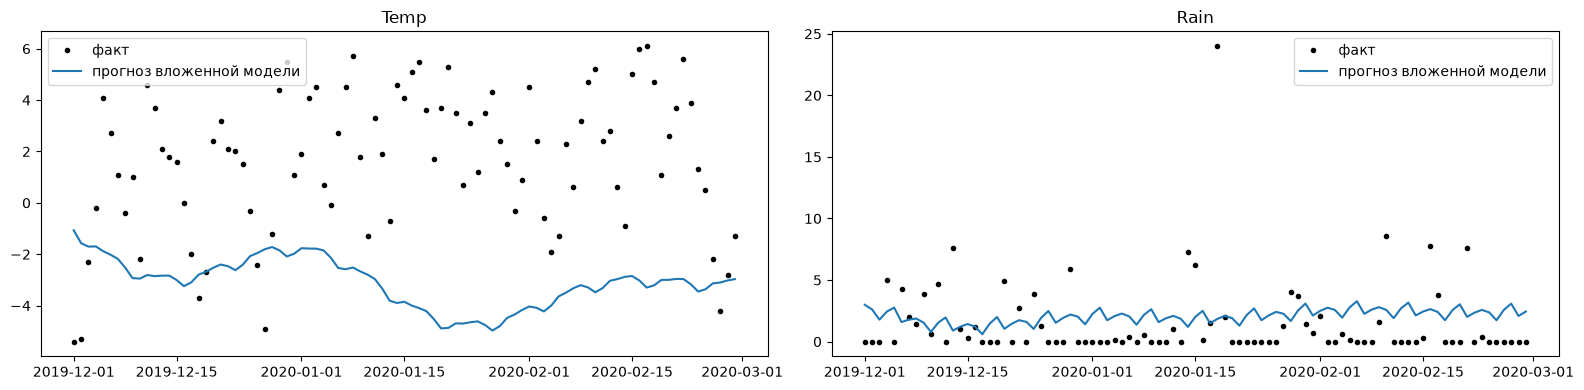

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, col in zip(axes, ["Temp", "Rain"]):
    predictor = m_nested.extra_regressors[col]["predictor"]
    ax.plot(test["ds"], test[col], ".", color="black", label="факт")
    ax.plot(test["ds"], predictor.predict(test[["ds"]])["yhat"], label="прогноз вложенной модели")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()

Документация формулирует это так: прогнозировать регрессор имеет смысл, только если **он предсказуемее целевого ряда** — иначе его ошибка просто переходит в ошибку $y$. Хорошие кандидаты: календарь, плановые события (промо, цены), агрегат верхнего уровня иерархии. Погода полезна на коротком горизонте, где есть метеопрогноз.

Регрессор с прогнозом корректно работает и в `cross_validation` (часть 4): на каждой отсечке вложенная модель учится только на прошлом, утечки нет.

## 2. Шоки: COVID-локдауны

Пешеходный поток в центре Мельбурна (один датчик, сумма за день). В 2020–2021 годах — четыре локдауна: два длинных и два коротких.

In [12]:
ped = pd.read_csv("../data/example_pedestrians_covid.csv", parse_dates=["ds"])
ped_future = pd.DataFrame({"ds": pd.date_range(ped["ds"].min(), ped["ds"].max() + pd.Timedelta(days=366))})

### 2.1. Дефолтная модель

Провалы и восстановление после них объясняются **трендом**: под них уходят изломы. А раз в истории были сильные изломы, модель считает, что они возможны и в будущем (часть 1, раздел 4): прогноз слишком оптимистичен, интервал огромный.

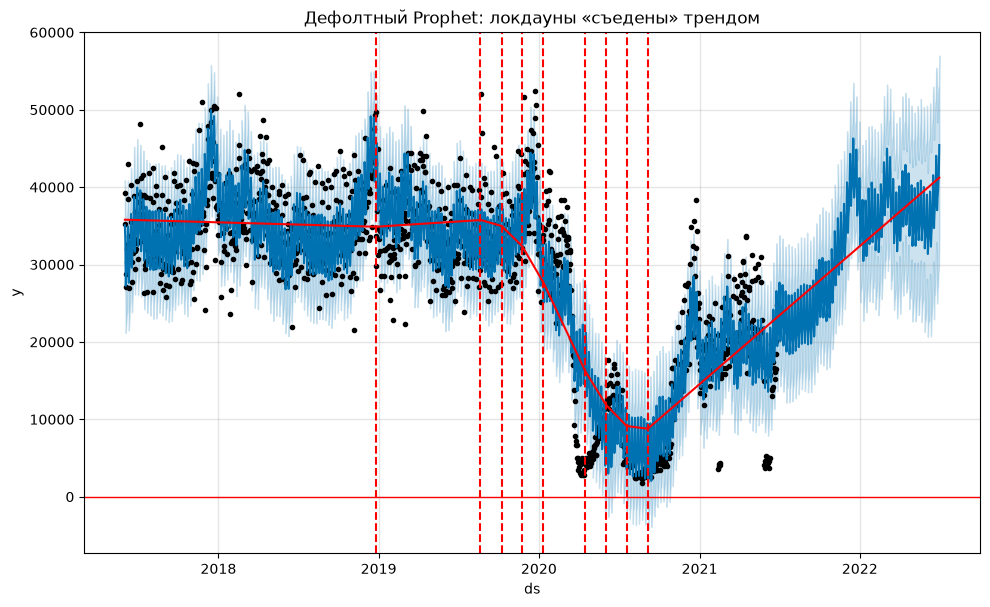

In [13]:
m_default = Prophet().fit(ped)
forecast_default = m_default.predict(ped_future)
fig = m_default.plot(forecast_default)
add_changepoints_to_plot(fig.gca(), m_default, forecast_default)
plt.axhline(0, color="red", lw=1)
plt.title("Дефолтный Prophet: локдауны «съедены» трендом");

### 2.2. Локдауны как разовые праздники

Опишем каждый локдаун как праздник с окном на всю его длительность и **без будущих дат** — модель оценит эффект в истории, но в прогноз его не перенесёт. `ds_upper` Prophet не использует, он только для подсчёта `upper_window` (верхняя граница окна включается).

In [14]:
lockdowns = pd.DataFrame({
    "holiday": ["lockdown_1", "lockdown_2", "lockdown_3", "lockdown_4"],
    "ds": pd.to_datetime(["2020-03-21", "2020-07-09", "2021-02-13", "2021-05-28"]),
    "ds_upper": pd.to_datetime(["2020-06-06", "2020-10-27", "2021-02-17", "2021-06-10"]),
    "lower_window": 0,
})
lockdowns["upper_window"] = (lockdowns["ds_upper"] - lockdowns["ds"]).dt.days
lockdowns

,holiday,ds,ds_upper,lower_window,upper_window
0,lockdown_1,2020-03-21,2020-06-06,0,77
1,lockdown_2,2020-07-09,2020-10-27,0,110
2,lockdown_3,2021-02-13,2021-02-17,0,4
3,lockdown_4,2021-05-28,2021-06-10,0,13


Внутри модели это $78 + 111 + 5 + 14 = 208$ индикаторных столбцов — по одному на день локдауна. Каждый день получает свой эффект, поэтому тренду объяснять провалы больше не нужно.

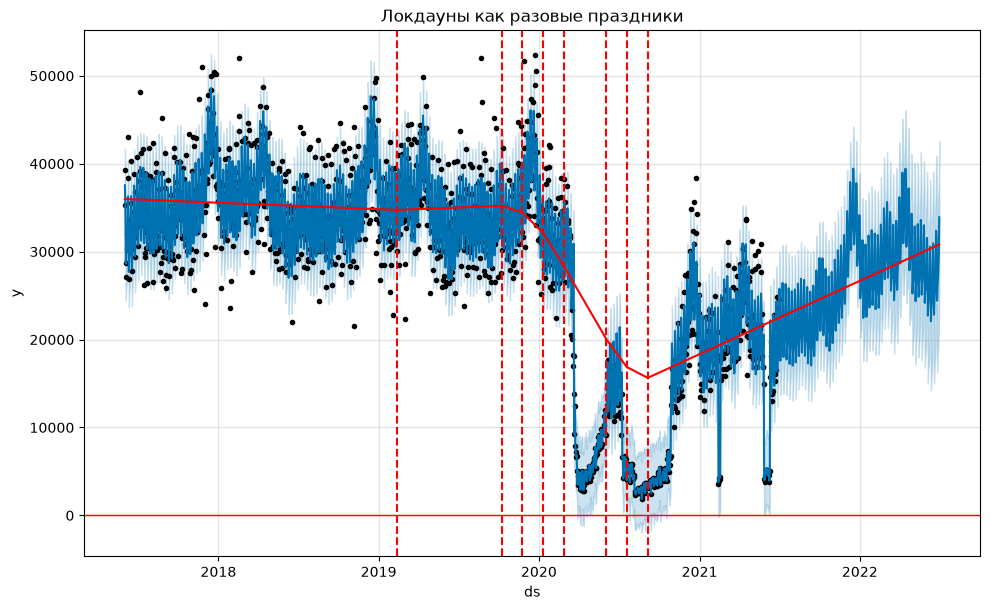

In [15]:
m_lockdown = Prophet(holidays=lockdowns).fit(ped)
forecast_lockdown = m_lockdown.predict(ped_future)
fig = m_lockdown.plot(forecast_lockdown)
add_changepoints_to_plot(fig.gca(), m_lockdown, forecast_lockdown)
plt.axhline(0, color="red", lw=1)
plt.title("Локдауны как разовые праздники");

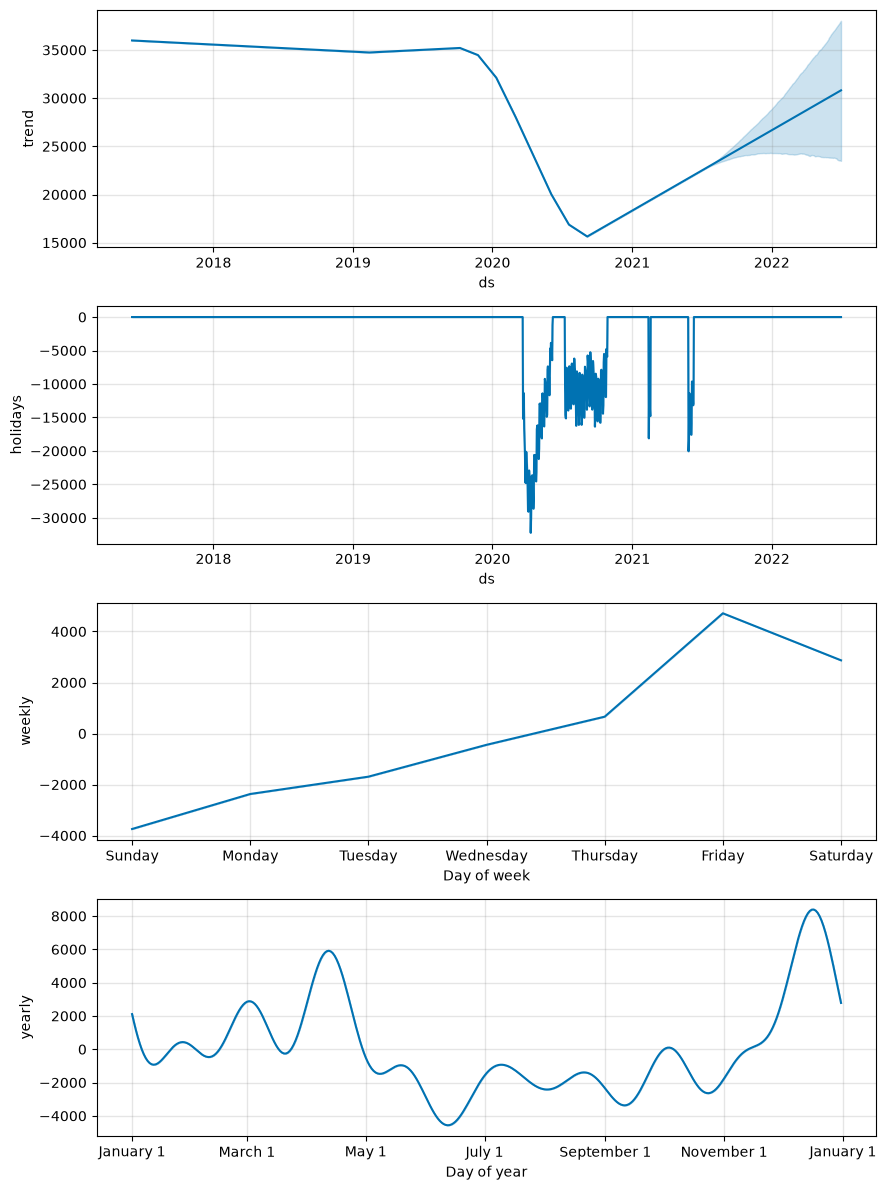

In [16]:
fig = m_lockdown.plot_components(forecast_lockdown)

Сравним тренды двух моделей напрямую:

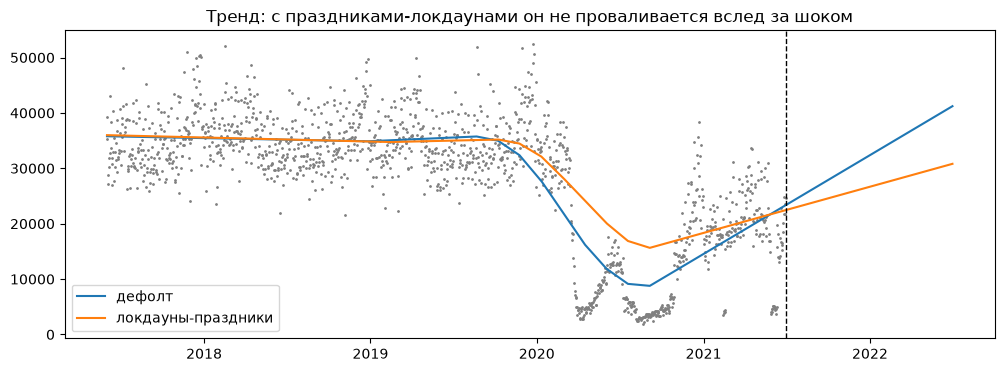

In [17]:
fig, ax = plt.subplots()
ax.plot(ped["ds"], ped["y"], ".", ms=2, color="grey")
for name, fc in [("дефолт", forecast_default), ("локдауны-праздники", forecast_lockdown)]:
    ax.plot(fc["ds"], fc["trend"], label=name)
ax.axvline(ped["ds"].max(), ls="--", color="black", lw=1)
ax.set_title("Тренд: с праздниками-локдаунами он не проваливается вслед за шоком")
ax.legend();

### 2.3. Проверка тренда: больше изломов после 2020

Если мы считаем, что «новая нормальность» после COVID важнее, тренду можно дать больше свободы именно там: 10 кандидатов на 2,5 года до пандемии, 15 — на 14 месяцев после, и `changepoint_prior_scale=1.0` (дефолт 0.05).

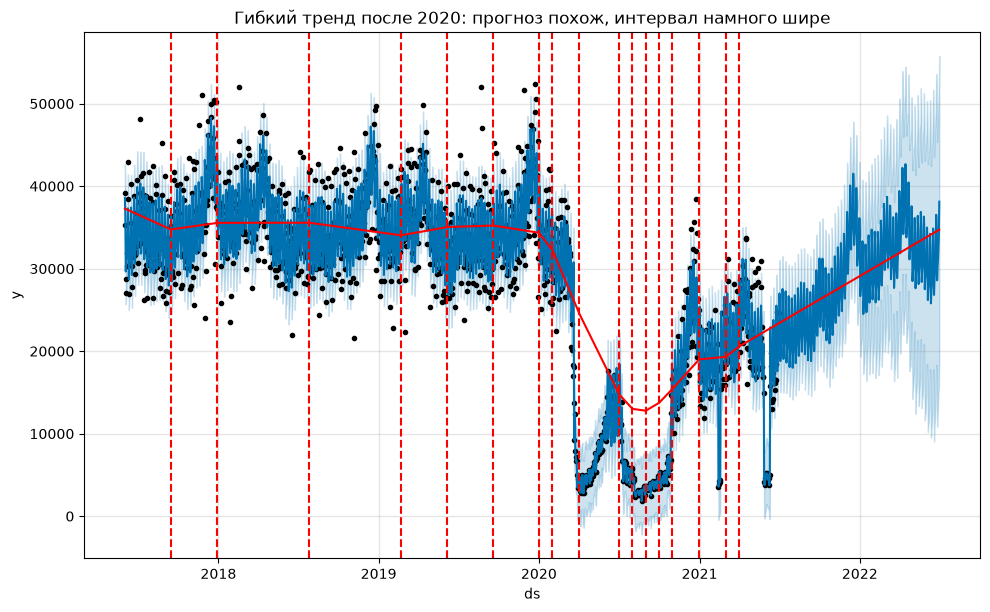

In [18]:
covid_changepoints = (
    pd.date_range("2017-06-02", "2020-01-01", periods=10).tolist()
    + pd.date_range("2020-02-01", "2021-04-01", periods=15).tolist()
)
m_flexible = Prophet(holidays=lockdowns, changepoints=covid_changepoints, changepoint_prior_scale=1.0).fit(ped)
forecast_flexible = m_flexible.predict(ped_future)
fig = m_flexible.plot(forecast_flexible)
add_changepoints_to_plot(fig.gca(), m_flexible, forecast_flexible)
plt.title("Гибкий тренд после 2020: прогноз похож, интервал намного шире");

Тренд ловит колебания между ослаблениями и ужесточениями ограничений, прогноз тренда похож на предыдущую модель, но из-за множества изломов в истории интервал сильно шире. Как точечную оценку документация эту модель не рекомендует; это пример того, как вписать в модель своё предположение о том, какие паттерны важны.

### 2.4. Сезонность до и после COVID

Недельный профиль мог измениться: удалёнка, меньше походов в бары в пятницу. Это условная сезонность из части 2: две недельные сезонности с флагами `pre_covid` / `post_covid`. Флаги нужны и в `future`.

In [19]:
def add_covid_flags(frame: pd.DataFrame) -> pd.DataFrame:
    pre_covid = frame["ds"] < pd.Timestamp("2020-03-21")
    return frame.assign(pre_covid=pre_covid, post_covid=~pre_covid)


m_seasonal = Prophet(holidays=lockdowns, weekly_seasonality=False)
m_seasonal.add_seasonality(name="weekly_pre_covid", period=7, fourier_order=3, condition_name="pre_covid")
m_seasonal.add_seasonality(name="weekly_post_covid", period=7, fourier_order=3, condition_name="post_covid")
m_seasonal.fit(add_covid_flags(ped))
forecast_seasonal = m_seasonal.predict(add_covid_flags(ped_future))

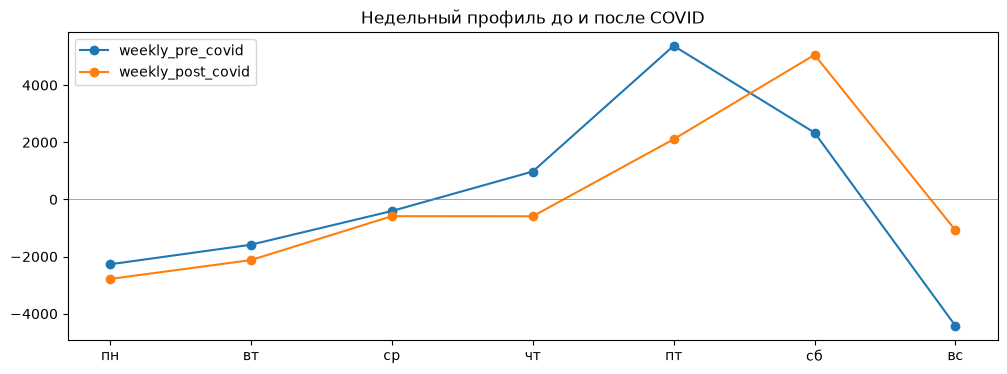

In [20]:
weekdays = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]
weekly_profile = (
    forecast_seasonal.assign(weekday=forecast_seasonal["ds"].dt.dayofweek)
    .groupby("weekday")[["weekly_pre_covid", "weekly_post_covid"]]
    .agg(lambda s: s[s != 0].mean())
    .set_axis(weekdays)
)
ax = weekly_profile.plot(marker="o", title="Недельный профиль до и после COVID")
ax.axhline(0, color="grey", lw=0.5);

До пандемии пик — пятница, после — суббота: люди работают из дома и реже выходят в город вечером в пятницу.

Другие подходы из документации: регрессор «индекс строгости ограничений» (если он есть и предсказуем) или удаление шоковых периодов / старой истории целиком. Общий совет — в условиях постоянно меняющихся правил чаще переобучать модель и честно сообщать, что неопределённость выросла.

## 3. Не-дневные данные

Prophet — модель в **непрерывном времени**: $t$ — вещественное число, сезонности — функции от $t$. Поэтому частота данных может быть любой, но задавать прогноз можно только там, где модель видела данные.

### 3.1. Внутридневные данные: температура в Йосемити (5 минут)

При внутридневных `ds` дневная сезонность (`period=1`, 4 гармоники) включается автоматически. Горизонт `make_future_dataframe` задаём с `freq="h"`.

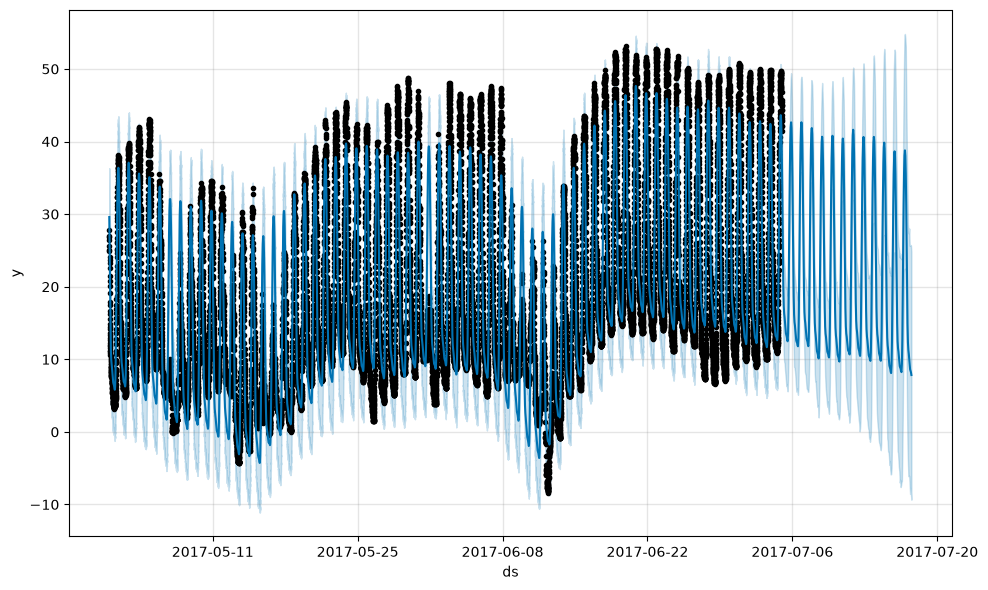

In [21]:
yosemite = pd.read_csv("../data/example_yosemite_temps.csv", parse_dates=["ds"])
m = Prophet(changepoint_prior_scale=0.01).fit(yosemite)
yosemite_future = m.make_future_dataframe(periods=300, freq="h")
forecast = m.predict(yosemite_future)
fig = m.plot(forecast)

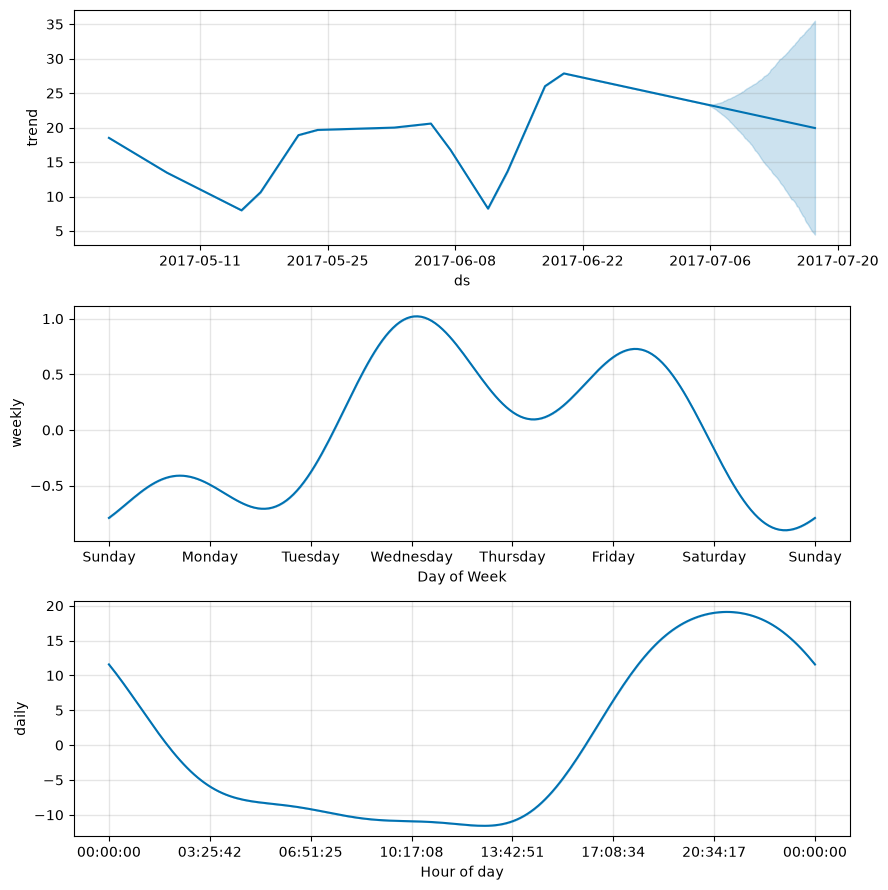

In [22]:
fig = m.plot_components(forecast)

### 3.2. Почасовой трафик: условный дневной профиль

Почасовой поток машин на I-94 (тот же ряд, что в блоке про TBATS): ~6 недель, дневная и недельная сезонности. Дефолтная дневная сезонность одна на все дни, хотя в будни два пика (утро и вечер), а в выходные — один, днём. Разделим её условием будни/выходные и сравним на последней неделе.

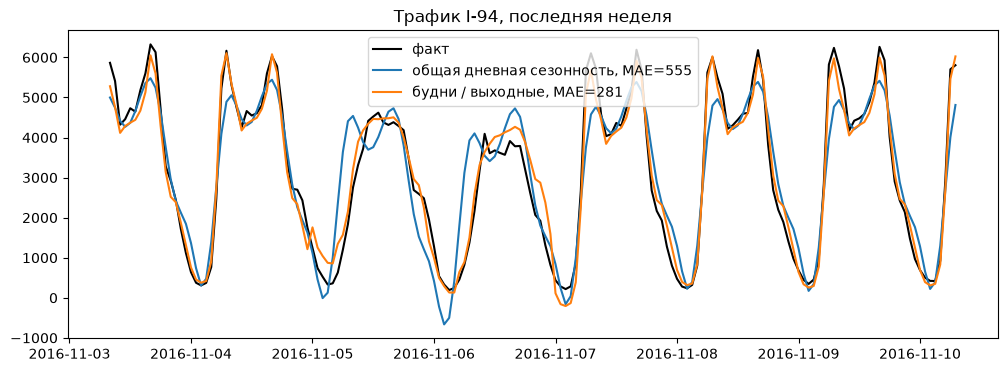

In [23]:
traffic = pd.read_csv("../data/daily_traffic.csv", parse_dates=["date_time"]).rename(
    columns={"date_time": "ds", "traffic_volume": "y"}
)


def add_weekend_flags(frame: pd.DataFrame) -> pd.DataFrame:
    weekend = frame["ds"].dt.dayofweek >= 5
    return frame.assign(weekend=weekend, weekday=~weekend)


traffic = add_weekend_flags(traffic)
cutoff = traffic["ds"].max() - pd.Timedelta(days=7)
traffic_train, traffic_test = traffic[traffic["ds"] <= cutoff], traffic[traffic["ds"] > cutoff]

m_common = Prophet().fit(traffic_train)
m_split = Prophet(daily_seasonality=False)
m_split.add_seasonality(name="daily_weekday", period=1, fourier_order=10, condition_name="weekday")
m_split.add_seasonality(name="daily_weekend", period=1, fourier_order=10, condition_name="weekend")
m_split.fit(traffic_train)

fig, ax = plt.subplots()
ax.plot(traffic_test["ds"], traffic_test["y"], color="black", label="факт")
for name, model in [("общая дневная сезонность", m_common), ("будни / выходные", m_split)]:
    fc = model.predict(traffic_test)
    ax.plot(fc["ds"], fc["yhat"], label=f"{name}, MAE={mae(traffic_test['y'], fc['yhat']):.0f}")
ax.set_title("Трафик I-94, последняя неделя")
ax.legend();

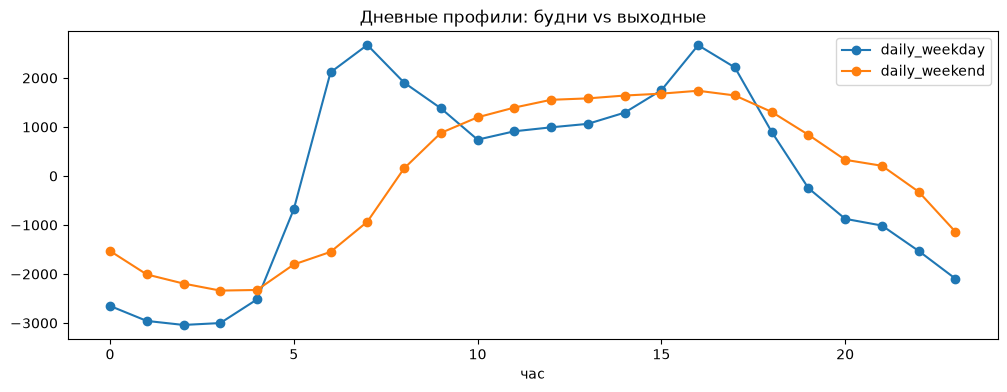

In [24]:
one_day = pd.DataFrame({"ds": pd.date_range("2016-11-07", periods=24, freq="h")})
fig, ax = plt.subplots()
for name, is_weekend in [("daily_weekday", False), ("daily_weekend", True)]:
    components = m_split.predict(one_day.assign(weekend=is_weekend, weekday=not is_weekend))
    ax.plot(range(24), components[name], marker="o", label=name)
ax.set(xlabel="час", title="Дневные профили: будни vs выходные")
ax.legend();

Ошибка падает примерно вдвое: в будни — утренний и вечерний пики, в выходные — плавный дневной горб. Аналогично можно сделать сезонность для каждого дня недели — или признать, что сезонности 24 × 168 удобнее описывать моделями вроде TBATS / MSTL (сравнение — в части 4).

### 3.3. Регулярные пропуски

Пусть в данных Йосемити есть только часы с 0:00 до 6:00. Модель обучится, но дневная сезонность на остальные 18 часов **ничем не ограничена** — гармоники Фурье между точками могут делать что угодно.

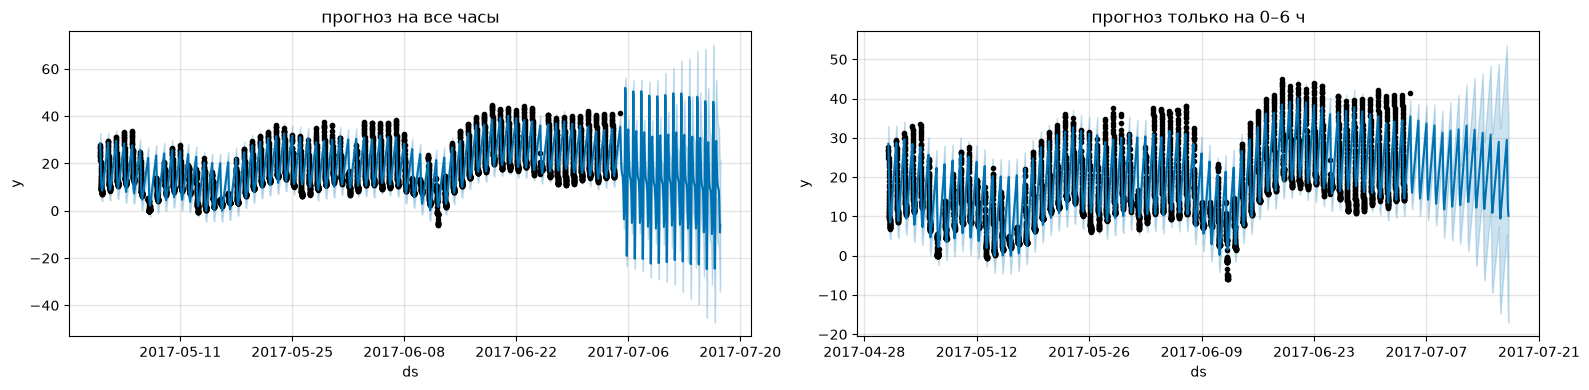

In [25]:
yosemite_night = yosemite[yosemite["ds"].dt.hour < 6]
m = Prophet().fit(yosemite_night)
night_future = m.make_future_dataframe(periods=300, freq="h")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (title, fut) in zip(axes, [
    ("прогноз на все часы", night_future),
    ("прогноз только на 0–6 ч", night_future[night_future["ds"].dt.hour < 6]),
]):
    m.plot(m.predict(fut), ax=ax)
    ax.set_title(title)
plt.tight_layout()

Решение — прогнозировать только там, где есть история. Тот же принцип для рядов «только будни»: не просить прогноз на выходные.

### 3.4. Месячные данные

Розничные продажи в США по месяцам. Если обучить на месячных данных и попросить **дневной** прогноз, получится то же, что с пропусками: годовая сезонность видела только первое число каждого месяца, между ними она не определена.

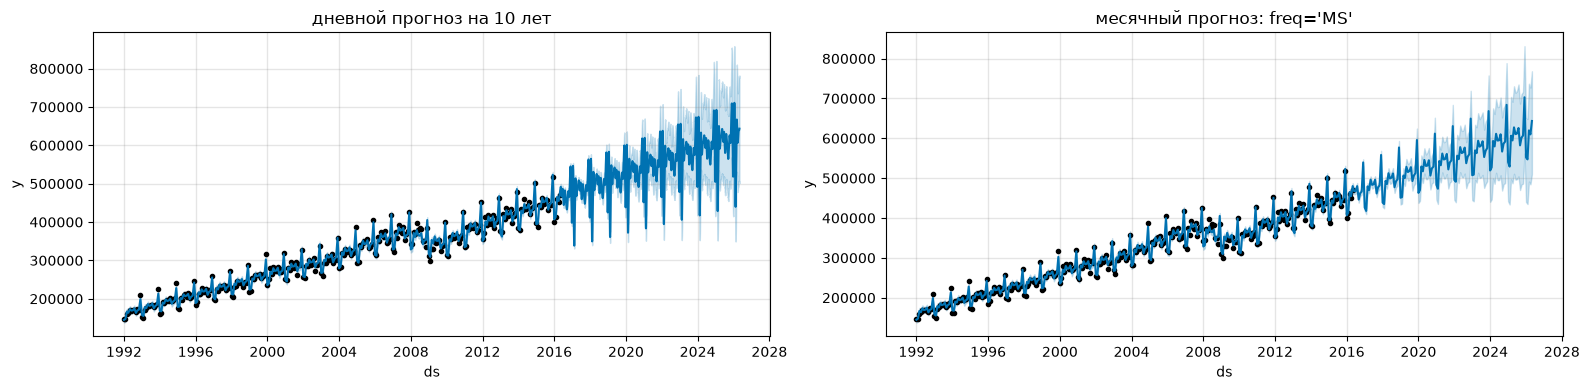

In [26]:
retail = pd.read_csv("../data/example_retail_sales.csv", parse_dates=["ds"])
m = Prophet(seasonality_mode="multiplicative").fit(retail)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (title, fut) in zip(axes, [
    ("дневной прогноз на 10 лет", m.make_future_dataframe(periods=3652)),
    ("месячный прогноз: freq='MS'", m.make_future_dataframe(periods=120, freq="MS")),
]):
    m.plot(m.predict(fut), ax=ax)
    ax.set_title(title)
plt.tight_layout()

Правило: прогноз — с той же частотой, что история (`freq="MS"` — начало месяца; подходит любая [частота pandas](https://pandas.pydata.org/docs/user_guide/timeseries.html#offset-aliases)).

Для месячных данных у годовой сезонности есть альтернатива без проблемы «между точками»: 12 бинарных регрессоров `is_jan`, …, `is_dec` через `add_regressor` (и `yearly_seasonality=False`) — обычные сезонные дамми вместо Фурье-приближения.

**Праздники на агрегированных данных.** Эффект праздника применяется к конкретной дате. В недельном ряду с точками по воскресеньям праздник в понедельник просто не попадёт ни в одну точку. Дату нужно перенести на ту точку истории, к которой относится эффект. Впрочем, на недельных и месячных данных большинство праздников уже поглощает годовая сезонность; отдельно стоит задавать только «плавающие» (Пасха, Чёрная пятница), которые попадают в разные недели.

## Итоги

- **Регрессор** — ещё один столбец $X$; бинарный регрессор с известным будущим эквивалентен празднику.
- **Будущее регрессора** — главная ловушка: факт вместо прогноза даёт утечку и завышенное качество. Честно — прогноз регрессора (`regressor_predictor=True`), и он полезен, только если регрессор предсказуемее $y$.
- **Шоки** — разовые праздники без будущих дат: эффект уходит из тренда, прогноз и интервалы становятся разумнее. Изменения после шока — через сетку изломов и условные сезонности.
- **Не-дневные данные** — модель в непрерывном времени: прогнозировать только там, где есть история (те же часы, та же частота); для месячных данных — `freq="MS"` или сезонные дамми.

Дальше (часть 4): честная валидация (`cross_validation`), тюнинг и сравнение с бейзлайнами.